In [1]:
%matplotlib inline
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}
%config InlineBackend.figure_formats = ["retina"]

import json
import math
import sys

import matplotlib.pyplot as plt
import numpy as np
sys.path.insert(0, "../../../skills/academic-figure/assets")  # the skill's style files
import paper  # registers the bundled Inter font
from paper import fit_height, mark_value, smooth, darken, lighten, text_color

colors = paper.use_design("../../../skills/academic-figure/assets/DESIGN.md")  # the style from DESIGN.md's tokens; colors["series-1"], colors["ours"], …

## radar-chart

**Figure 3: Accuracy (%) of three 8–9B models on six benchmarks.** Numbers give Ours-8B's accuracy on each benchmark. Ours-8B has the most balanced profile, with its largest gains on GSM8K (79.6 vs. 75.1) and MATH (41.5 vs. 36.6) over the best other model.

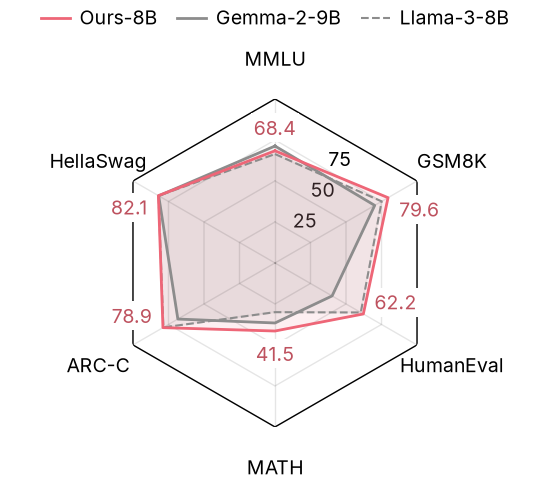

In [2]:
data = json.load(open("../data/radar-chart.json"))
names = data["benchmarks"]
n = len(names)
angles = np.linspace(0, 2 * np.pi, n, endpoint=False)
loop = np.r_[angles, angles[:1]]
rings = [25, 50, 75, 100]

fig, ax = plt.subplots(figsize=(2.75, 2.75), subplot_kw={"projection": "polar"})
ax.set_theta_offset(np.pi / 2)
ax.set_theta_direction(-1)
ax.grid(False)
ax.spines["polar"].set_visible(False)
for r in rings:
    ax.plot(loop, [r] * (n + 1), color=colors["ink"], alpha=0.1, linewidth=0.5)
for a in angles:
    ax.plot([a, a], [0, rings[-1]], color=colors["ink"], alpha=0.1, linewidth=0.5)
ax.plot(loop, [rings[-1]] * (n + 1), color=colors["ink"], linewidth=0.5)

handles = {}
for name, color, style in [("Gemma-2-9B", colors["neutral"], "-"),
                           ("Llama-3-8B", colors["neutral"], "--"),
                           ("Ours-8B", colors["ours"], "-")]:
    values = data["scores"][name]
    width = 1 if style == "-" else paper.dashed_width
    handles[name], = ax.plot(loop, np.r_[values, values[:1]], color=color, linestyle=style, linewidth=width, label=name)
    ax.fill(angles, values, color=color, alpha=0.1)

for angle, v in zip(angles, data["scores"]["Ours-8B"]):
    side = np.sin(angle) if abs(np.sin(angle)) > 0.1 else 0
    up = np.cos(angle) if side == 0 else 0
    ax.annotate(f"{v:#.3g}", (angle, v), xytext=(4 * np.sign(side), 4 * np.sign(up)), textcoords="offset points",
                ha="left" if side > 0 else "right" if side < 0 else "center",
                va=("top" if np.cos(angle) > 0 else "bottom") if side else ("bottom" if up > 0 else "top"),
                color=darken(colors["ours"]), bbox=dict(facecolor="white", edgecolor="none", pad=1))

ax.set_ylim(0, rings[-1])
ax.set_xticks(angles, labels=names)
ax.tick_params(axis="x", pad=6)
ax.set_yticks([r * np.cos(np.pi / n) for r in rings[:-1]], labels=[str(r) for r in rings[:-1]])
ax.set_rlabel_position(180 / n)

order = ["Ours-8B", "Gemma-2-9B", "Llama-3-8B"]
fig.legend([handles[m] for m in order], order, loc="outside upper center", ncol=3, frameon=False, borderaxespad=0)

fit_height(fig, ax)
fig.savefig("../outputs/radar-chart.pdf")
fig.savefig("../outputs/radar-chart.png")
plt.show()